In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.pricing import (
    black_scholes_call,
    monte_carlo_call,
    monte_carlo_call_antithetic
)

S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

prix_reference = black_scholes_call(S0, K, T, r, sigma)

print("Prix Black-Scholes :", prix_reference)



Prix Black-Scholes : 10.450583572185565


In [5]:
n_values = [100, 500, 1000, 5000, 10000, 50000, 100000]

results = []

for N in n_values:

    # Monte-Carlo standard
    standard = monte_carlo_call(
        S0, K, T, r, sigma,
        n_simulations=N,
        seed=42
    )

    # Monte-Carlo antithétique
    antithetic = monte_carlo_call_antithetic(
        S0, K, T, r, sigma,
        n_pairs=N // 2,
        seed=42
    )

    results.append({
        "N": N,
        "Prix standard": standard["price"],
        "Prix antithétique": antithetic["price"],
        "Erreur standard": standard["standard_error"],
        "Erreur antithétique": antithetic["standard_error"]
    })

df = pd.DataFrame(results)

display(df)

,N,Prix standard,Prix antithétique,Erreur standard,Erreur antithétique
0,100,7.825768,8.286818,1.011962,0.733399
1,500,9.868363,9.843097,0.635871,0.433104
2,1000,9.911980,10.000398,0.448345,0.313601
3,5000,10.168920,10.450949,0.205861,0.150468
4,10000,10.345182,10.410052,0.147663,0.104872
5,50000,10.457692,10.454935,0.066143,0.046749
6,100000,10.420541,10.467314,0.046770,0.033077


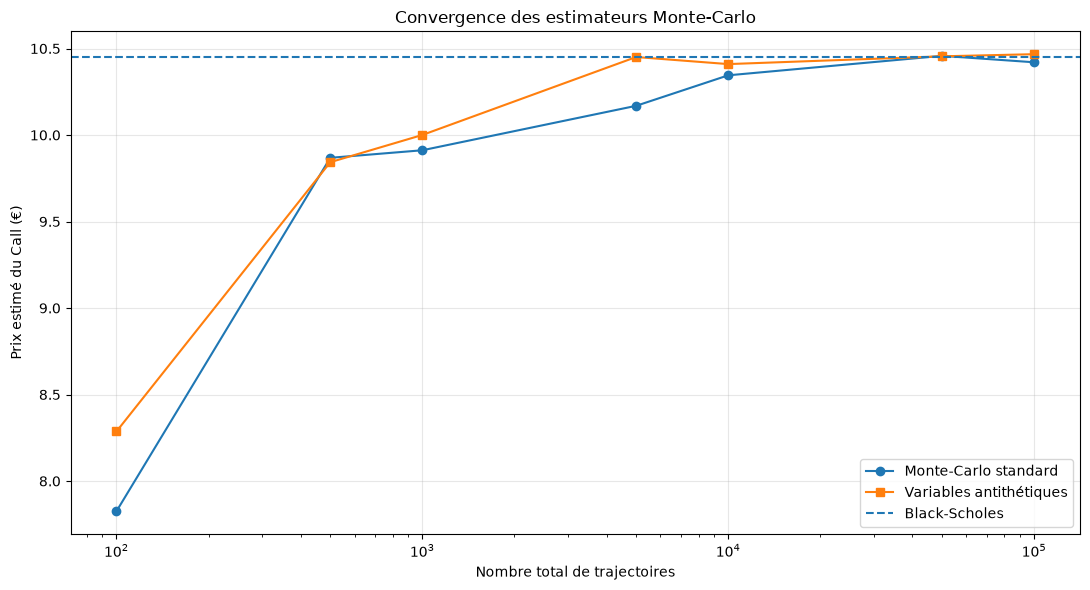

In [6]:

plt.figure(figsize=(11, 6))

plt.plot(
    df["N"],
    df["Prix standard"],
    marker="o",
    label="Monte-Carlo standard"
)

plt.plot(
    df["N"],
    df["Prix antithétique"],
    marker="s",
    label="Variables antithétiques"
)

plt.axhline(
    y=prix_reference,
    linestyle="--",
    label="Black-Scholes"
)

plt.xscale("log")

plt.xlabel("Nombre total de trajectoires")
plt.ylabel("Prix estimé du Call (€)")

plt.title("Convergence des estimateurs Monte-Carlo")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../figures/convergence_monte_carlo.png", dpi=300)
plt.show()


In [13]:
from src.pricing import monte_carlo_asian_call

asian = monte_carlo_asian_call(
    S0=100,
    K=100,
    T=1,
    r=0.05,
    sigma=0.20,
    n_simulations=50_000,
    n_steps=252,
    seed=42
)

print("Prix du Call asiatique :", asian["price"])
print("Erreur standard :", asian["standard_error"])
print("Intervalle de confiance :", asian["confidence_interval"])

Prix du Call asiatique : 5.838918415222987
Erreur standard : 0.03602069975020574
Intervalle de confiance : (5.768317843712584, 5.90951898673339)


In [14]:
from src.pricing import monte_carlo_asian_call

asian = monte_carlo_asian_call(
    S0=100,
    K=100,
    T=1,
    r=0.05,
    sigma=0.20,
    n_simulations=50_000,
    n_steps=252,
    seed=42
)

print("PRICING OPTION ASIATIQUE")
print("------------------------")
print("Prix :", round(asian["price"], 6))
print("Erreur standard :", round(asian["standard_error"], 6))
print("IC 95 % :", asian["confidence_interval"])

PRICING OPTION ASIATIQUE
------------------------
Prix : 5.838918
Erreur standard : 0.036021
IC 95 % : (5.768317843712584, 5.90951898673339)


In [16]:
european = black_scholes_call(
    100, 100, 1, 0.05, 0.20
)

print("Call européen :", round(european, 6))
print("Call asiatique :", round(asian["price"], 6))

print(
    "Différence :",
    round(european - asian["price"], 6)
)

Call européen : 10.450584
Call asiatique : 5.838918
Différence : 4.611665


In [17]:
from src.pricing import (
    black_scholes_call,
    monte_carlo_asian_call
)

# Paramètres du marché
S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

# Prix européen
european = black_scholes_call(
    S0, K, T, r, sigma
)

# Prix asiatique
asian = monte_carlo_asian_call(
    S0, K, T, r, sigma,
    n_simulations=100_000,
    n_steps=252,
    seed=42
)

print("PRICING COMPARATIF")
print("--------------------------")
print("Call européen :", round(european, 6))
print("Call asiatique :", round(asian["price"], 6))
print("Erreur standard :", round(asian["standard_error"], 6))
print("IC 95 % :", asian["confidence_interval"])
print("Différence :", round(european - asian["price"], 6))

PRICING COMPARATIF
--------------------------
Call européen : 10.450584
Call asiatique : 5.786512
Erreur standard : 0.025338
IC 95 % : (5.736849828012812, 5.836173953258334)
Différence : 4.664072


In [18]:
steps_values = [12, 52, 252]

asian_results = []

for steps in steps_values:

    result = monte_carlo_asian_call(
        S0, K, T, r, sigma,
        n_simulations=100_000,
        n_steps=steps,
        seed=42
    )

    asian_results.append({
        "Observations": steps,
        "Prix asiatique": result["price"],
        "Erreur standard": result["standard_error"]
    })

df_asian = pd.DataFrame(asian_results)

display(df_asian)

,Observations,Prix asiatique,Erreur standard
0,12,6.164991,0.026990
1,52,5.910310,0.025893
2,252,5.786512,0.025338


In [23]:
from src.greeks import delta_call, delta_put

S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

call_delta = delta_call(S0, K, T, r, sigma)
put_delta = delta_put(S0, K, T, r, sigma)

print("CALL DELTA :", call_delta)
print("PUT DELTA :", put_delta)
print("Somme des Deltas :", call_delta - put_delta)

CALL DELTA : 0.6368306511756191
PUT DELTA : -0.3631693488243809
Somme des Deltas : 1.0


In [30]:
from src.greeks import gamma

gamma_value = gamma(100, 100, 1, 0.05, 0.20)

print("GAMMA :", gamma_value)

GAMMA : 0.018762017345846895


In [31]:
from src.pricing import black_scholes_call

S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

h = 0.01

gamma_numerical = (
    black_scholes_call(S0+h, K, T, r, sigma)
    - 2*black_scholes_call(S0, K, T, r, sigma)
    + black_scholes_call(S0-h, K, T, r, sigma)
) / h**2

gamma_analytical = gamma(S0, K, T, r, sigma)

print("Gamma analytique :", gamma_analytical)
print("Gamma numérique :", gamma_numerical)
print("Erreur :", abs(gamma_analytical-gamma_numerical))

Gamma analytique : 0.018762017345846895
Gamma numérique : 0.018762017077733617
Erreur : 2.681132781068296e-10


In [34]:
from src.greeks import vega

vega_value = vega(100, 100, 1, 0.05, 0.20)

print("VEGA :", vega_value)
print("VEGA par point de volatilité :", vega_value / 100)

VEGA : 37.52403469169379
VEGA par point de volatilité : 0.3752403469169379


In [35]:
from src.pricing import black_scholes_call
from src.greeks import vega

S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

h = 0.0001

vega_numerical = (
    black_scholes_call(S0, K, T, r, sigma+h)
    - black_scholes_call(S0, K, T, r, sigma-h)
) / (2*h)

vega_analytical = vega(S0, K, T, r, sigma)

print("Vega analytique :", vega_analytical)
print("Vega numérique :", vega_numerical)
print("Erreur :", abs(vega_analytical-vega_numerical))

Vega analytique : 37.52403469169379
Vega numérique : 37.52403438721075
Erreur : 3.0448304499941514e-07


In [39]:
tc = greeks.theta_call(100, 100, 1, 0.05, 0.20)
tp = greeks.theta_put(100, 100, 1, 0.05, 0.20)

print("THETA CALL :", tc)
print("THETA PUT :", tp)

THETA CALL : -6.414027546438197
THETA PUT : -1.657880423934626


In [40]:

from src.pricing import black_scholes_call, black_scholes_put
from src.greeks import theta_call, theta_put

S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

h = 0.0001

# Theta numérique du Call
theta_call_num = (
    black_scholes_call(S0, K, T-h, r, sigma)
    - black_scholes_call(S0, K, T+h, r, sigma)
) / (2*h)

# Theta numérique du Put
theta_put_num = (
    black_scholes_put(S0, K, T-h, r, sigma)
    - black_scholes_put(S0, K, T+h, r, sigma)
) / (2*h)

# Theta analytique
theta_call_ana = theta_call(S0, K, T, r, sigma)
theta_put_ana = theta_put(S0, K, T, r, sigma)

print("CALL")
print("Analytique :", theta_call_ana)
print("Numérique :", theta_call_num)
print("Erreur :", abs(theta_call_ana-theta_call_num))

print("\nPUT")
print("Analytique :", theta_put_ana)
print("Numérique :", theta_put_num)
print("Erreur :", abs(theta_put_ana-theta_put_num))


CALL
Analytique : -6.414027546438197
Numérique : -6.414027551358004
Erreur : 4.919806784187131e-09

PUT
Analytique : -1.657880423934626
Numérique : -1.6578804288513993
Erreur : 4.916773210794645e-09


In [43]:
from src.greeks import rho_call, rho_put

rho_c = rho_call(100, 100, 1, 0.05, 0.20)
rho_p = rho_put(100, 100, 1, 0.05, 0.20)

print("RHO CALL :", rho_c)
print("RHO PUT :", rho_p)

print("RHO CALL par 1% :", rho_c / 100)
print("RHO PUT par 1% :", rho_p / 100)

RHO CALL : 53.232481545376345
RHO PUT : -41.89046090469506
RHO CALL par 1% : 0.5323248154537634
RHO PUT par 1% : -0.4189046090469506


In [44]:

from src.pricing import black_scholes_call, black_scholes_put
from src.greeks import rho_call, rho_put

S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

h = 0.0001

# Rho numérique Call
rho_call_num = (
    black_scholes_call(S0, K, T, r+h, sigma)
    - black_scholes_call(S0, K, T, r-h, sigma)
) / (2*h)

# Rho numérique Put
rho_put_num = (
    black_scholes_put(S0, K, T, r+h, sigma)
    - black_scholes_put(S0, K, T, r-h, sigma)
) / (2*h)

# Rho analytique
rho_call_ana = rho_call(S0, K, T, r, sigma)
rho_put_ana = rho_put(S0, K, T, r, sigma)

print("CALL")
print("Analytique :", rho_call_ana)
print("Numérique :", rho_call_num)
print("Erreur :", abs(rho_call_ana-rho_call_num))

print("\nPUT")
print("Analytique :", rho_put_ana)
print("Numérique :", rho_put_num)
print("Erreur :", abs(rho_put_ana-rho_put_num))


CALL
Analytique : 53.232481545376345
Numérique : 53.23248077413467
Erreur : 7.712416731919802e-07

PUT
Analytique : -41.89046090469506
Numérique : -41.89046183441292
Erreur : 9.297178564793285e-07


In [47]:
from src.greeks import calculate_greeks
import pandas as pd

call_greeks = calculate_greeks(
    100, 100, 1, 0.05, 0.20,
    option_type="call"
)

put_greeks = calculate_greeks(
    100, 100, 1, 0.05, 0.20,
    option_type="put"
)

df_greeks = pd.DataFrame({
    "Call": call_greeks,
    "Put": put_greeks
})

display(df_greeks)

,Call,Put
Delta,0.636831,-0.363169
Gamma,0.018762,0.018762
Vega,37.524035,37.524035
Theta,-6.414028,-1.657880
Rho,53.232482,-41.890461


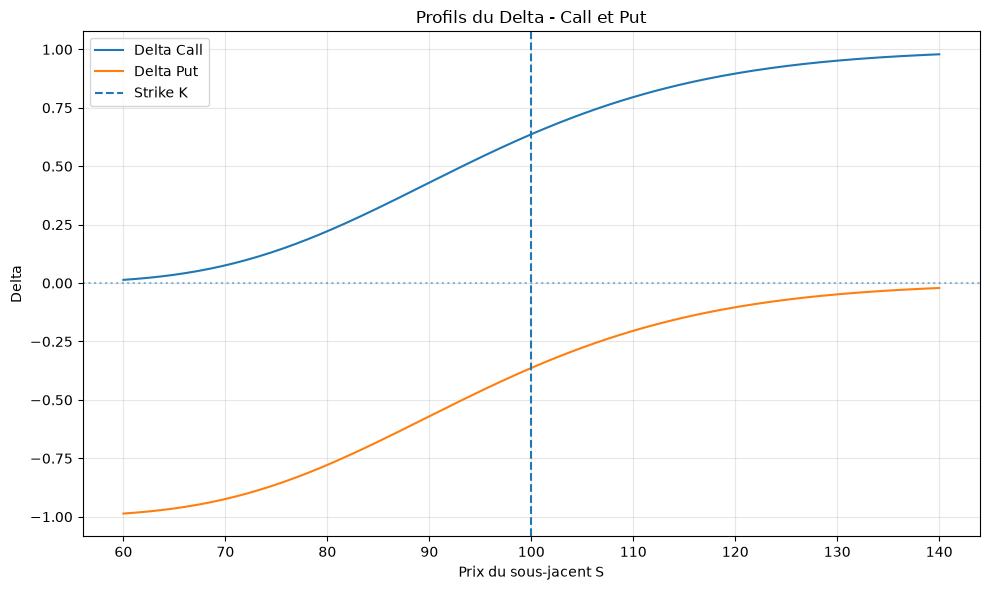

In [48]:

import numpy as np
import matplotlib.pyplot as plt

from src.greeks import delta_call, delta_put

# Paramètres
K = 100
T = 1
r = 0.05
sigma = 0.20

# Prix du sous-jacent
S_values = np.linspace(60, 140, 200)

# Calcul des Deltas
call_deltas = [
    delta_call(S, K, T, r, sigma)
    for S in S_values
]

put_deltas = [
    delta_put(S, K, T, r, sigma)
    for S in S_values
]

# Graphique
plt.figure(figsize=(10, 6))

plt.plot(
    S_values,
    call_deltas,
    label="Delta Call"
)

plt.plot(
    S_values,
    put_deltas,
    label="Delta Put"
)

plt.axvline(
    K,
    linestyle="--",
    label="Strike K"
)

plt.axhline(0, linestyle=":", alpha=0.5)

plt.xlabel("Prix du sous-jacent S")
plt.ylabel("Delta")

plt.title("Profils du Delta - Call et Put")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/delta_profile.png", dpi=300)
plt.show()


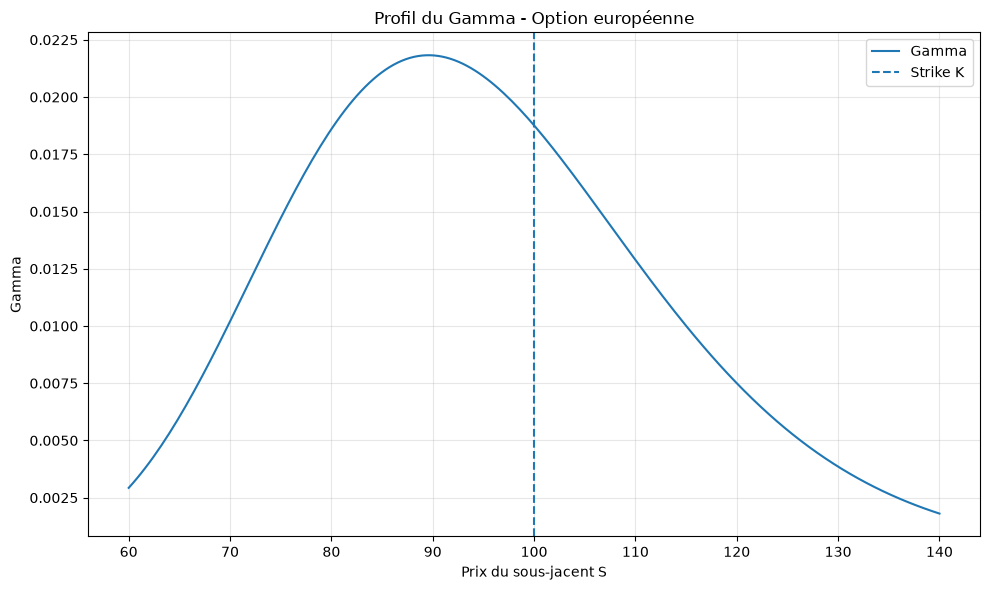

In [49]:

import numpy as np
import matplotlib.pyplot as plt

from src.greeks import gamma

# Paramètres
K = 100
T = 1
r = 0.05
sigma = 0.20

# Prix du sous-jacent
S_values = np.linspace(60, 140, 200)

# Calcul du Gamma
gamma_values = [
    gamma(S, K, T, r, sigma)
    for S in S_values
]

# Graphique
plt.figure(figsize=(10, 6))

plt.plot(
    S_values,
    gamma_values,
    label="Gamma"
)

plt.axvline(
    K,
    linestyle="--",
    label="Strike K"
)

plt.xlabel("Prix du sous-jacent S")
plt.ylabel("Gamma")

plt.title("Profil du Gamma - Option européenne")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/gamma_profile.png", dpi=300)
plt.show()


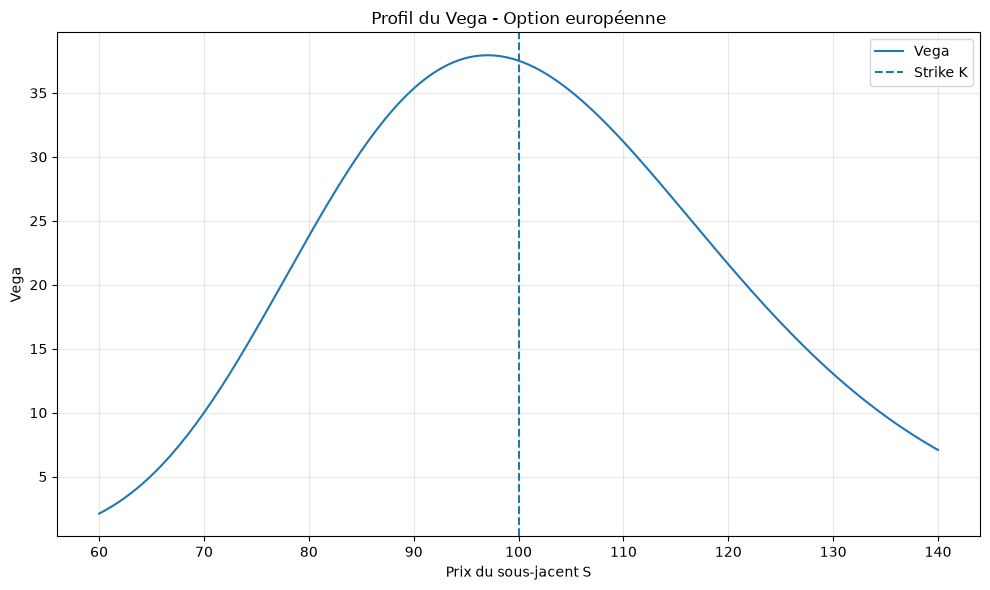

In [50]:

import numpy as np
import matplotlib.pyplot as plt

from src.greeks import vega

# Paramètres
K = 100
T = 1
r = 0.05
sigma = 0.20

# Prix du sous-jacent
S_values = np.linspace(60, 140, 200)

# Calcul du Vega
vega_values = [
    vega(S, K, T, r, sigma)
    for S in S_values
]

# Graphique
plt.figure(figsize=(10, 6))

plt.plot(
    S_values,
    vega_values,
    label="Vega"
)

plt.axvline(
    K,
    linestyle="--",
    label="Strike K"
)

plt.xlabel("Prix du sous-jacent S")
plt.ylabel("Vega")

plt.title("Profil du Vega - Option européenne")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/vega_profile.png", dpi=300)
plt.show()


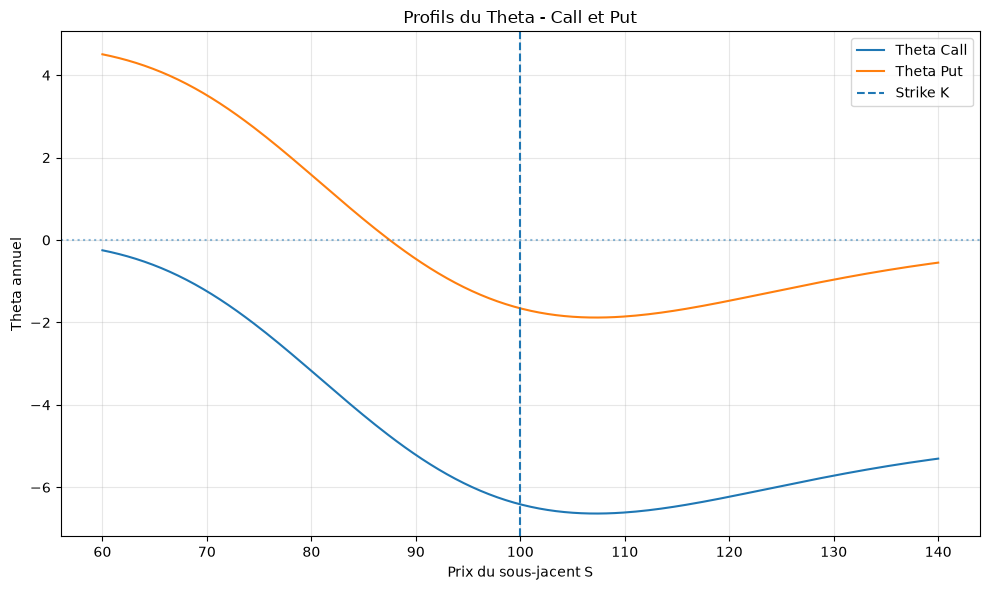

In [51]:

import numpy as np
import matplotlib.pyplot as plt

from src.greeks import theta_call, theta_put

# Paramètres
K = 100
T = 1
r = 0.05
sigma = 0.20

# Prix du sous-jacent
S_values = np.linspace(60, 140, 200)

# Calcul des Theta
call_theta_values = [
    theta_call(S, K, T, r, sigma)
    for S in S_values
]

put_theta_values = [
    theta_put(S, K, T, r, sigma)
    for S in S_values
]

# Graphique
plt.figure(figsize=(10, 6))

plt.plot(
    S_values,
    call_theta_values,
    label="Theta Call"
)

plt.plot(
    S_values,
    put_theta_values,
    label="Theta Put"
)

plt.axvline(
    K,
    linestyle="--",
    label="Strike K"
)

plt.axhline(0, linestyle=":", alpha=0.5)

plt.xlabel("Prix du sous-jacent S")
plt.ylabel("Theta annuel")

plt.title("Profils du Theta - Call et Put")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/theta_profile.png", dpi=300)
plt.show()


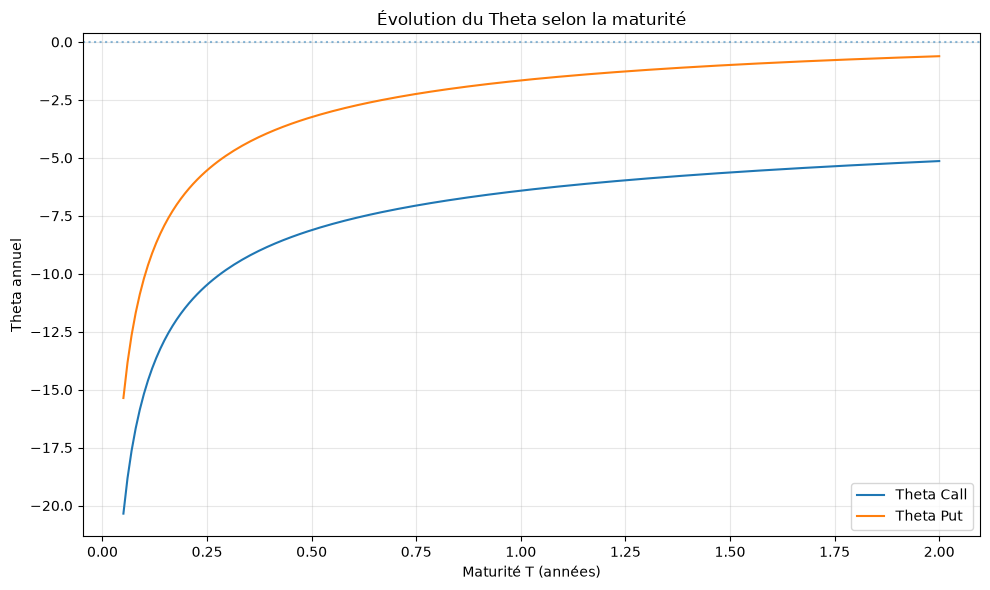

In [52]:

import numpy as np
import matplotlib.pyplot as plt

from src.greeks import theta_call, theta_put

# Paramètres
S0 = 100
K = 100
r = 0.05
sigma = 0.20

# Maturités en années
T_values = np.linspace(0.05, 2, 200)

# Calcul des Theta
call_theta_values = [
    theta_call(S0, K, T, r, sigma)
    for T in T_values
]

put_theta_values = [
    theta_put(S0, K, T, r, sigma)
    for T in T_values
]

# Graphique
plt.figure(figsize=(10, 6))

plt.plot(
    T_values,
    call_theta_values,
    label="Theta Call"
)

plt.plot(
    T_values,
    put_theta_values,
    label="Theta Put"
)

plt.axhline(0, linestyle=":", alpha=0.5)

plt.xlabel("Maturité T (années)")
plt.ylabel("Theta annuel")

plt.title("Évolution du Theta selon la maturité")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/theta_maturity.png", dpi=300)
plt.show()


In [53]:
from src.pricing import black_scholes_call

# Paramètres du marché
S0 = 100
K = 100
T = 1
r = 0.05

# Volatilité réelle utilisée pour générer le prix
true_sigma = 0.25

# Prix de marché simulé
market_price = black_scholes_call(
    S0, K, T, r, true_sigma
)

print("Prix du Call observé :", market_price)

Prix du Call observé : 12.335998930368717


In [55]:
implied_sigma = implied_volatility_call(
    market_price=market_price,
    S0=S0,
    K=K,
    T=T,
    r=r,
    initial_sigma=0.20
)

print("Volatilité réelle :", true_sigma)
print("Volatilité implicite :", implied_sigma)
print("Erreur :", abs(true_sigma - implied_sigma))

Volatilité réelle : 0.25
Volatilité implicite : 0.24999999999999983
Erreur : 1.6653345369377348e-16


In [56]:
import importlib
import src.volatility as volatility

importlib.reload(volatility)

<module 'src.volatility' from 'c:\\Users\\Admin\\options-pricer-delta-hedging\\src\\volatility.py'>

In [57]:
implied_sigma = volatility.implied_volatility_call(
    market_price=market_price,
    S0=S0,
    K=K,
    T=T,
    r=r,
    initial_sigma=0.20
)

print("Volatilité réelle :", true_sigma)
print("Volatilité implicite :", implied_sigma)
print("Erreur :", abs(true_sigma - implied_sigma))

Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2502455393
Itération 3 : sigma = 0.2500000029
Itération 4 : sigma = 0.2500000000
Volatilité réelle : 0.25
Volatilité implicite : 0.24999999999999983
Erreur : 1.6653345369377348e-16


In [58]:
from src.pricing import black_scholes_put

S0 = 100
K = 100
T = 1
r = 0.05

true_sigma_put = 0.30

market_put_price = black_scholes_put(
    S0, K, T, r, true_sigma_put
)

print("Prix du Put observé :", market_put_price)

Prix du Put observé : 9.354197236057232


In [62]:
from src.volatility import implied_volatility_put

implied_sigma_put = implied_volatility_put(
    market_price=market_put_price,
    S0=S0,
    K=K,
    T=T,
    r=r,
    initial_sigma=0.20
)

print("\nVolatilité réelle :", true_sigma_put)
print("Volatilité implicite :", implied_sigma_put)

print(
    "Erreur :",
    abs(true_sigma_put - implied_sigma_put)
)

Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.3007533237
Itération 3 : sigma = 0.3000000048
Itération 4 : sigma = 0.3000000000

Volatilité réelle : 0.3
Volatilité implicite : 0.30000000000000004
Erreur : 5.551115123125783e-17


In [63]:
import importlib
import src.volatility as volatility

importlib.reload(volatility)

implied_sigma_put = volatility.implied_volatility_put(
    market_price=market_put_price,
    S0=S0,
    K=K,
    T=T,
    r=r,
    initial_sigma=0.20
)

print("Volatilité implicite :", implied_sigma_put)

Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.3007533237
Itération 3 : sigma = 0.3000000048
Itération 4 : sigma = 0.3000000000
Volatilité implicite : 0.30000000000000004


In [64]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.pricing import black_scholes_call

# Paramètres
S0 = 100
T = 1
r = 0.05

# Différents strikes
strikes = np.array([80, 85, 90, 95, 100,
                    105, 110, 115, 120])

# Volatilité utilisée pour chaque strike
market_volatilities = (
    0.20 + 0.0002 * (strikes - 100)**2
)

# Génération des prix des Calls
market_prices = []

for K, sigma in zip(strikes, market_volatilities):

    price = black_scholes_call(
        S0, K, T, r, sigma
    )

    market_prices.append(price)

# Tableau récapitulatif
data = pd.DataFrame({
    "Strike": strikes,
    "Volatilite utilisee": market_volatilities,
    "Prix du Call": market_prices
})

display(data.round(6))


,Strike,Volatilite utilisee,Prix du Call
0,80,0.280,26.020252
1,85,0.245,21.482604
2,90,0.220,17.257579
3,95,0.205,13.512928
4,100,0.200,10.450584
5,105,0.205,8.219680
6,110,0.220,6.833048
7,115,0.245,6.185392
8,120,0.280,6.143940


In [65]:

from src.volatility import implied_volatility_call

implied_volatilities = []

for K, price in zip(strikes, market_prices):

    sigma_imp = implied_volatility_call(
        market_price=price,
        S0=S0,
        K=K,
        T=T,
        r=r,
        initial_sigma=0.20
    )

    implied_volatilities.append(sigma_imp)

# Comparaison
data["Volatilite implicite"] = implied_volatilities

display(data.round(6))


Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.3050411989
Itération 3 : sigma = 0.2808540957
Itération 4 : sigma = 0.2800012054
Itération 5 : sigma = 0.2800000000
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2499271578
Itération 3 : sigma = 0.2450349031
Itération 4 : sigma = 0.2450000018
Itération 5 : sigma = 0.2450000000
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2205477880
Itération 3 : sigma = 0.2200003300
Itération 4 : sigma = 0.2200000000
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2050150404
Itération 3 : sigma = 0.2050000001
Itération 1 : sigma = 0.2000000000
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2049993721
Itération 3 : sigma = 0.2050000000
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2200363687
Itération 3 : sigma = 0.2200000001
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2457866085
Itération 3 : sigma = 0.2450001494
Itération 4 : sigma = 0.2450000000
Itération 1 : sigma 

,Strike,Volatilite utilisee,Prix du Call,Volatilite implicite
0,80,0.280,26.020252,0.280
1,85,0.245,21.482604,0.245
2,90,0.220,17.257579,0.220
3,95,0.205,13.512928,0.205
4,100,0.200,10.450584,0.200
5,105,0.205,8.219680,0.205
6,110,0.220,6.833048,0.220
7,115,0.245,6.185392,0.245
8,120,0.280,6.143940,0.280


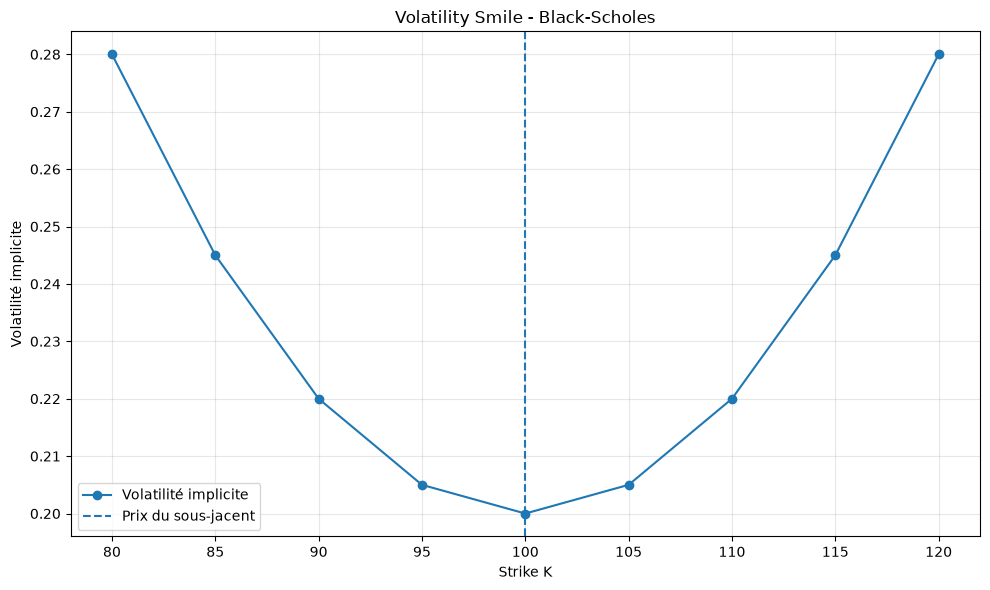

In [66]:

plt.figure(figsize=(10, 6))

plt.plot(
    strikes,
    implied_volatilities,
    marker="o",
    label="Volatilité implicite"
)

plt.axvline(
    S0,
    linestyle="--",
    label="Prix du sous-jacent"
)

plt.xlabel("Strike K")
plt.ylabel("Volatilité implicite")

plt.title("Volatility Smile - Black-Scholes")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/volatility_smile.png", dpi=300)

plt.show()


In [67]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.pricing import black_scholes_call

# Paramètres
S0 = 100
T = 1
r = 0.05

# Strikes
skew_strikes = np.array([
    80, 85, 90, 95, 100, 105, 110, 115, 120
])

# Volatilités asymétriques
skew_volatilities = (
    0.20 - 0.001 * (skew_strikes - 100)
)

# Calcul des prix
skew_prices = []

for K, sigma in zip(skew_strikes, skew_volatilities):

    price = black_scholes_call(
        S0, K, T, r, sigma
    )

    skew_prices.append(price)

# Tableau
skew_data = pd.DataFrame({
    "Strike": skew_strikes,
    "Volatilite utilisee": skew_volatilities,
    "Prix du Call": skew_prices
})

display(skew_data.round(6))


,Strike,Volatilite utilisee,Prix du Call
0,80,0.220,24.885659
1,85,0.215,20.785909
2,90,0.210,16.974944
3,95,0.205,13.512928
4,100,0.200,10.450584
5,105,0.195,7.822975
6,110,0.190,5.644765
7,115,0.185,3.907854
8,120,0.180,2.581981


In [68]:

from src.volatility import implied_volatility_call

skew_implied_volatilities = []

for K, price in zip(skew_strikes, skew_prices):

    sigma_imp = implied_volatility_call(
        market_price=price,
        S0=S0,
        K=K,
        T=T,
        r=r,
        initial_sigma=0.20
    )

    skew_implied_volatilities.append(sigma_imp)

skew_data["Volatilite implicite"] = (
    skew_implied_volatilities
)

display(skew_data.round(6))


Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2217816928
Itération 3 : sigma = 0.2200108114
Itération 4 : sigma = 0.2200000004
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2156002787
Itération 3 : sigma = 0.2150008038
Itération 4 : sigma = 0.2150000000
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2101424511
Itération 3 : sigma = 0.2100000259
Itération 4 : sigma = 0.2100000000
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2050150404
Itération 3 : sigma = 0.2050000001
Itération 1 : sigma = 0.2000000000
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.1949993825
Itération 3 : sigma = 0.1950000000
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.1900110401
Itération 3 : sigma = 0.1900000000
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.1851163878
Itération 3 : sigma = 0.1850000083
Itération 4 : sigma = 0.1850000000
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.1804689990
Itération 3 : sigma 

,Strike,Volatilite utilisee,Prix du Call,Volatilite implicite
0,80,0.220,24.885659,0.220
1,85,0.215,20.785909,0.215
2,90,0.210,16.974944,0.210
3,95,0.205,13.512928,0.205
4,100,0.200,10.450584,0.200
5,105,0.195,7.822975,0.195
6,110,0.190,5.644765,0.190
7,115,0.185,3.907854,0.185
8,120,0.180,2.581981,0.180


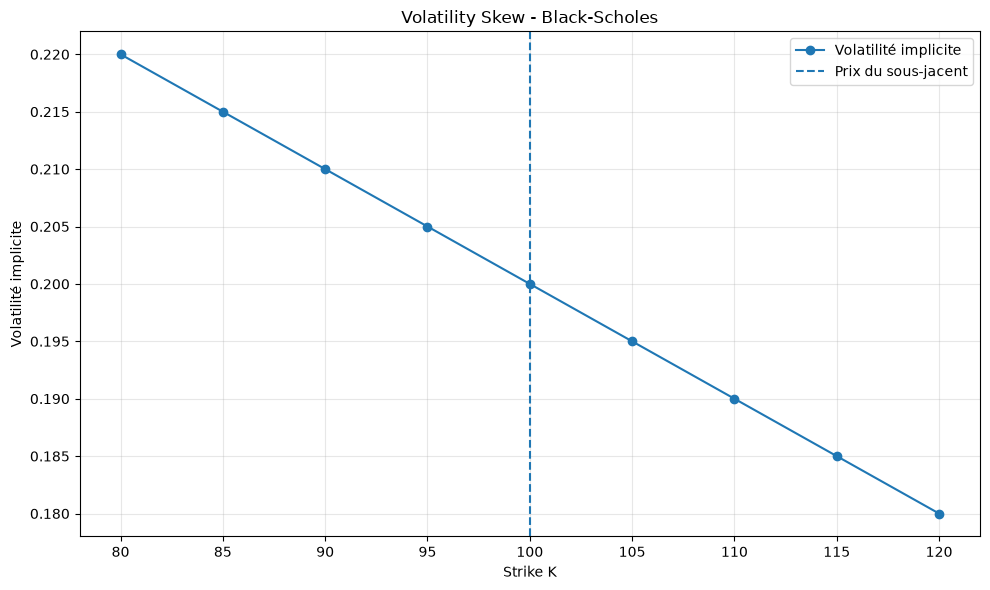

In [69]:

plt.figure(figsize=(10, 6))

plt.plot(
    skew_strikes,
    skew_implied_volatilities,
    marker="o",
    label="Volatilité implicite"
)

plt.axvline(
    S0,
    linestyle="--",
    label="Prix du sous-jacent"
)

plt.xlabel("Strike K")
plt.ylabel("Volatilité implicite")

plt.title("Volatility Skew - Black-Scholes")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/volatility_skew.png", dpi=300)

plt.show()


In [70]:

import yfinance as yf
import pandas as pd
import numpy as np

# Création de l'objet Apple
ticker = yf.Ticker("AAPL")

# Historique récent du cours
history = ticker.history(period="5d")

# Dernier cours de clôture disponible
S0 = float(history["Close"].dropna().iloc[-1])

# Dates d'expiration des options
expirations = ticker.options

print("ANALYSE APPLE (AAPL)")
print("--------------------")

print("Dernier cours disponible :", round(S0, 2), "$")

print("\nDates d'expiration disponibles :")

for date in expirations:
    print(date)

print("\nNombre d'expirations :", len(expirations))


ANALYSE APPLE (AAPL)
--------------------
Dernier cours disponible : 356.27 $

Dates d'expiration disponibles :
2026-11-16
2026-11-18
2026-11-20
2026-11-23
2026-11-25
2026-11-27
2026-12-04
2026-12-11
2026-12-18
2026-12-24
2026-12-31
2027-01-15
2027-02-19
2027-03-19
2027-04-16
2027-06-17
2027-09-17
2027-12-17
2028-01-21
2028-03-17
2028-06-16
2028-12-15
2029-01-19

Nombre d'expirations : 23


In [71]:

# Choix de l'expiration
expiration = "2026-12-18"

# Vérification de la disponibilité
if expiration not in expirations:
    raise ValueError("Date d'expiration indisponible.")

# Récupération de la chaîne d'options
option_chain = ticker.option_chain(expiration)

# Séparation des Calls et des Puts
calls = option_chain.calls.copy()
puts = option_chain.puts.copy()

print("Nombre de Calls :", len(calls))
print("Nombre de Puts :", len(puts))

# Affichage des premières observations
display(calls.head())
display(puts.head())


Nombre de Calls : 102
Nombre de Puts : 88


,contractSymbol,lastTradeDate,strike,lastPrice,bid,ask,change,percentChange,volume,openInterest,impliedVolatility,inTheMoney,contractSize,currency
0,AAPL261218C00005000,2026-11-13 20:28:15+00:00,5.0,352.00,349.55,352.65,11.279999,3.310636,13,0,8.742192,True,REGULAR,USD
1,AAPL261218C00010000,2026-08-07 19:52:50+00:00,10.0,303.27,0.00,0.00,0.000000,0.000000,2,0,0.000010,True,REGULAR,USD
2,AAPL261218C00015000,2026-08-07 19:52:50+00:00,15.0,298.33,0.00,0.00,0.000000,0.000000,2,0,0.000010,True,REGULAR,USD
3,AAPL261218C00020000,2026-08-07 18:06:08+00:00,20.0,292.93,0.00,0.00,0.000000,0.000000,2,0,0.000010,True,REGULAR,USD
4,AAPL261218C00025000,2026-11-12 15:29:23+00:00,25.0,332.89,329.65,333.20,0.000000,0.000000,3,3,3.425783,True,REGULAR,USD


,contractSymbol,lastTradeDate,strike,lastPrice,bid,ask,change,percentChange,volume,openInterest,impliedVolatility,inTheMoney,contractSize,currency
0,AAPL261218P00005000,2026-11-03 14:50:00+00:00,5.0,0.01,0.0,0.01,0.0,0.0,1.0,131,4.125005,False,REGULAR,USD
1,AAPL261218P00010000,2026-08-05 13:30:02+00:00,10.0,0.19,0.0,0.01,0.0,0.0,10.0,3101,3.437501,False,REGULAR,USD
2,AAPL261218P00015000,2026-06-30 14:42:33+00:00,15.0,0.46,0.0,1.02,0.0,0.0,6.0,640,4.859379,False,REGULAR,USD
3,AAPL261218P00020000,2026-10-23 16:33:19+00:00,20.0,0.01,0.0,0.01,0.0,0.0,42.0,2999,2.750003,False,REGULAR,USD
4,AAPL261218P00025000,2026-09-25 18:46:40+00:00,25.0,0.01,0.0,0.01,0.0,0.0,1002.0,1601,2.500004,False,REGULAR,USD


In [72]:

# Calcul du prix moyen Bid-Ask
calls["mid_price"] = (calls["bid"] + calls["ask"]) / 2
puts["mid_price"] = (puts["bid"] + puts["ask"]) / 2

# Conservation des cotations exploitables
calls_clean = calls[
    (calls["bid"] > 0) &
    (calls["ask"] >= calls["bid"]) &
    (calls["ask"] > 0)
].copy()

puts_clean = puts[
    (puts["bid"] > 0) &
    (puts["ask"] >= puts["bid"]) &
    (puts["ask"] > 0)
].copy()

# Sélection des strikes proches du cours Apple
lower_bound = 0.80 * S0
upper_bound = 1.20 * S0

calls_clean = calls_clean[
    calls_clean["strike"].between(lower_bound, upper_bound)
]

puts_clean = puts_clean[
    puts_clean["strike"].between(lower_bound, upper_bound)
]

print("CALLS exploitables :")
display(calls_clean[
    ["strike", "bid", "ask", "mid_price",
     "impliedVolatility", "volume", "openInterest"]
].head(15))

print("PUTS exploitables :")
display(puts_clean[
    ["strike", "bid", "ask", "mid_price",
     "impliedVolatility", "volume", "openInterest"]
].head(15))


CALLS exploitables :


,strike,bid,ask,mid_price,impliedVolatility,volume,openInterest
54,290.0,67.10,68.70,67.900,0.525517,104,14552
55,295.0,61.20,64.05,62.625,0.511235,8,4270
56,300.0,57.60,59.10,58.350,0.479803,44,21488
57,305.0,52.75,54.55,53.650,0.466802,2,4558
58,310.0,47.75,49.60,48.675,0.434088,13,6719
59,315.0,42.85,44.85,43.850,0.409247,20,5084
60,320.0,37.95,39.60,38.775,0.364020,63,10714
61,325.0,33.50,35.15,34.325,0.348395,41,7670
62,330.0,29.60,30.75,30.175,0.331061,142,21321
63,335.0,24.85,26.15,25.500,0.304328,51,8149


PUTS exploitables :


,strike,bid,ask,mid_price,impliedVolatility,volume,openInterest
54,290.0,0.32,0.39,0.355,0.355719,125.0,10210
55,295.0,0.41,0.45,0.430,0.338874,42.0,10846
56,300.0,0.53,0.55,0.540,0.325446,2318.0,45049
57,305.0,0.66,0.68,0.670,0.312385,150.0,16769
58,310.0,0.80,0.85,0.825,0.299812,1164.0,16940
59,315.0,1.03,1.11,1.070,0.290168,1657.0,10448
60,320.0,1.33,1.40,1.365,0.277839,5864.0,32188
61,325.0,1.73,1.80,1.765,0.266975,1171.0,6383
62,330.0,2.27,2.35,2.310,0.257332,3058.0,20800
63,335.0,2.95,3.05,3.000,0.247383,1316.0,7926


In [73]:

# Calcul de la maturité

valuation_date = history.index[-1].date()
expiration_date = pd.to_datetime(expiration).date()

days_to_expiration = (
    expiration_date - valuation_date
).days

T = days_to_expiration / 365

print("Date de référence :", valuation_date)
print("Date d'expiration :", expiration_date)
print("Nombre de jours :", days_to_expiration)
print("Maturité T :", T)


Date de référence : 2026-11-13
Date d'expiration : 2026-12-18
Nombre de jours : 35
Maturité T : 0.0958904109589041


In [74]:

# Définition de la zone proche de la monnaie

lower_bound = 0.95 * S0
upper_bound = 1.05 * S0

# Sélection des Calls
calls_atm = calls_clean[
    calls_clean["strike"].between(
        lower_bound, upper_bound
    )
].copy()

# Sélection des Puts
puts_atm = puts_clean[
    puts_clean["strike"].between(
        lower_bound, upper_bound
    )
].copy()

# Tri par strike
calls_atm = calls_atm.sort_values("strike")
puts_atm = puts_atm.sort_values("strike")

print("CALLS proches de la monnaie")
display(calls_atm[
    ["strike", "bid", "ask", "mid_price",
     "impliedVolatility", "volume", "openInterest"]
])

print("PUTS proches de la monnaie")
display(puts_atm[
    ["strike", "bid", "ask", "mid_price",
     "impliedVolatility", "volume", "openInterest"]
])


CALLS proches de la monnaie


,strike,bid,ask,mid_price,impliedVolatility,volume,openInterest
64,340.0,20.85,21.85,21.350,0.283210,462,15329
65,345.0,17.00,18.10,17.550,0.271858,448,8514
66,350.0,13.90,14.60,14.250,0.260200,910,27560
67,355.0,10.95,11.25,11.100,0.244881,835,6010
68,360.0,8.30,8.50,8.400,0.235237,7413,27858
69,365.0,6.05,6.20,6.125,0.226906,919,7415
70,370.0,4.20,4.40,4.300,0.220955,1296,19274


PUTS proches de la monnaie


,strike,bid,ask,mid_price,impliedVolatility,volume,openInterest
64,340.0,3.80,3.95,3.875,0.237495,1928.0,15344
65,345.0,4.95,5.10,5.025,0.227608,1652.0,9065
66,350.0,6.40,6.65,6.525,0.219979,4230.0,10931
67,355.0,8.20,8.50,8.350,0.210701,2314.0,3830
68,360.0,10.55,10.80,10.675,0.202095,945.0,2272
69,365.0,13.15,13.80,13.475,0.199410,155.0,532
70,370.0,16.15,17.10,16.625,0.193184,169.0,550


In [75]:

from src.volatility import (
    implied_volatility_call,
    implied_volatility_put
)

# Taux sans risque retenu comme hypothèse
r = 0.05

# Fonction de calcul des volatilités implicites
def calculate_market_iv(data, option_type):

    data = data.copy()
    implied_vols = []

    for _, row in data.iterrows():

        K = float(row["strike"])
        market_price = float(row["mid_price"])

        try:

            if option_type == "call":

                sigma = implied_volatility_call(
                    market_price,
                    S0,
                    K,
                    T,
                    r
                )

            elif option_type == "put":

                sigma = implied_volatility_put(
                    market_price,
                    S0,
                    K,
                    T,
                    r
                )

            else:
                raise ValueError("Type inconnu")

        except (ValueError, RuntimeError, OverflowError):
            sigma = np.nan

        implied_vols.append(sigma)

    data["iv_model"] = implied_vols

    # Comparaison avec Yahoo Finance
    data["iv_yahoo"] = data["impliedVolatility"]

    data["ecart"] = (
        data["iv_model"] - data["iv_yahoo"]
    )

    return data


# Calcul pour les Calls et les Puts
calls_results = calculate_market_iv(
    calls_atm, "call"
)

puts_results = calculate_market_iv(
    puts_atm, "put"
)

print("RESULTATS CALLS")
display(calls_results[
    ["strike", "mid_price", "iv_yahoo",
     "iv_model", "ecart"]
].round(6))

print("RESULTATS PUTS")
display(puts_results[
    ["strike", "mid_price", "iv_yahoo",
     "iv_model", "ecart"]
].round(6))


Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2334026153
Itération 3 : sigma = 0.2318461899
Itération 4 : sigma = 0.2318435342
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2264464159
Itération 3 : sigma = 0.2259125979
Itération 4 : sigma = 0.2259124236
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2246775606
Itération 3 : sigma = 0.2245009962
Itération 4 : sigma = 0.2245009889
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2177782686
Itération 3 : sigma = 0.2177658197
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2123328722
Itération 3 : sigma = 0.2123302950
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2070171958
Itération 3 : sigma = 0.2070056536
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2023003813
Itération 3 : sigma = 0.2022966842
Itération 1 : sigma = 0.2000000000
Itération 2 : sigma = 0.2472928352
Itération 3 : sigma = 0.2443991164
Itération 4 : sigma = 0.2443913538
Itération 1 : sigma 

,strike,mid_price,iv_yahoo,iv_model,ecart
64,340.0,21.350,0.283210,0.231844,-0.051367
65,345.0,17.550,0.271858,0.225912,-0.045945
66,350.0,14.250,0.260200,0.224501,-0.035699
67,355.0,11.100,0.244881,0.217766,-0.027115
68,360.0,8.400,0.235237,0.212330,-0.022907
69,365.0,6.125,0.226906,0.207006,-0.019900
70,370.0,4.300,0.220955,0.202297,-0.018658


RESULTATS PUTS


,strike,mid_price,iv_yahoo,iv_model,ecart
64,340.0,3.875,0.237495,0.244391,0.006896
65,345.0,5.025,0.227608,0.236368,0.008760
66,350.0,6.525,0.219979,0.229803,0.009825
67,355.0,8.350,0.210701,0.222779,0.012078
68,360.0,10.675,0.202095,0.218402,0.016307
69,365.0,13.475,0.199410,0.215612,0.016202
70,370.0,16.625,0.193184,0.211610,0.018426


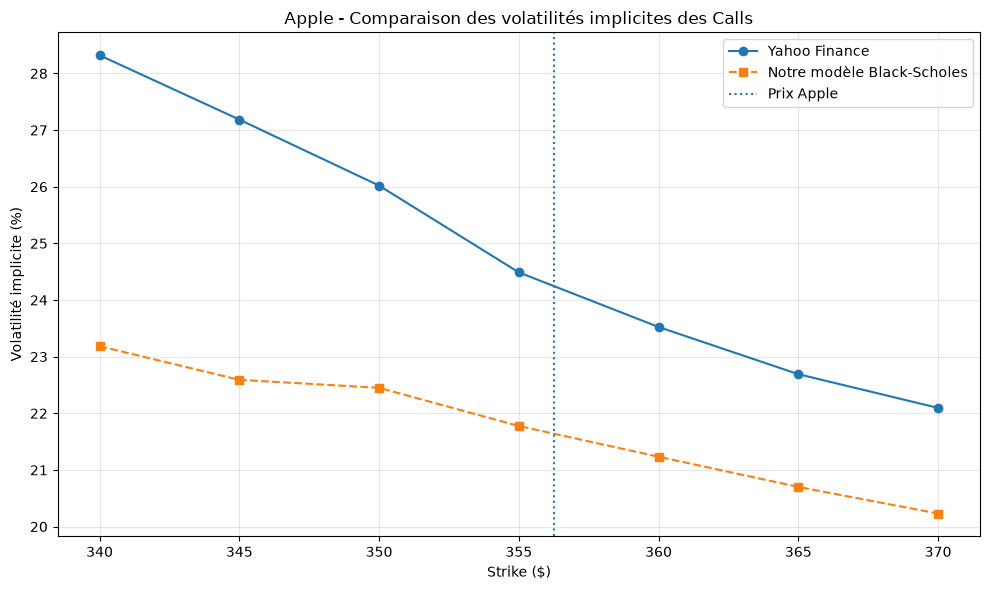

In [76]:

plt.figure(figsize=(10, 6))

plt.plot(
    calls_results["strike"],
    calls_results["iv_yahoo"] * 100,
    marker="o",
    label="Yahoo Finance"
)

plt.plot(
    calls_results["strike"],
    calls_results["iv_model"] * 100,
    marker="s",
    linestyle="--",
    label="Notre modèle Black-Scholes"
)

plt.axvline(S0, linestyle=":", label="Prix Apple")

plt.xlabel("Strike ($)")
plt.ylabel("Volatilité implicite (%)")
plt.title("Apple - Comparaison des volatilités implicites des Calls")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/aapl_calls_comparison.png", dpi=300)
plt.show()


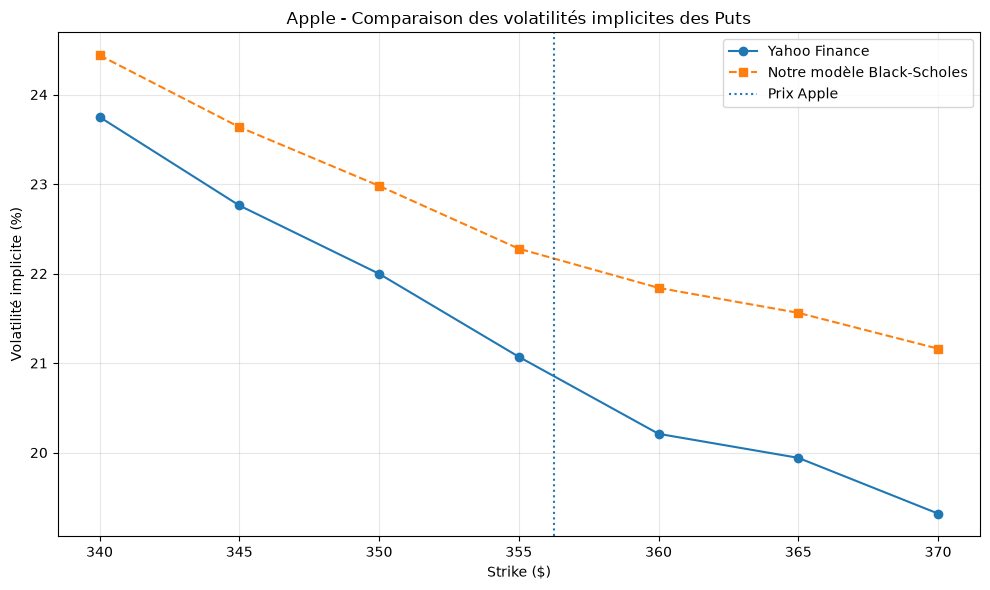

In [77]:

plt.figure(figsize=(10, 6))

plt.plot(
    puts_results["strike"],
    puts_results["iv_yahoo"] * 100,
    marker="o",
    label="Yahoo Finance"
)

plt.plot(
    puts_results["strike"],
    puts_results["iv_model"] * 100,
    marker="s",
    linestyle="--",
    label="Notre modèle Black-Scholes"
)

plt.axvline(S0, linestyle=":", label="Prix Apple")

plt.xlabel("Strike ($)")
plt.ylabel("Volatilité implicite (%)")
plt.title("Apple - Comparaison des volatilités implicites des Puts")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/aapl_puts_comparison.png", dpi=300)
plt.show()


In [79]:

# Calcul de l'erreur absolue moyenne

mae_calls = np.mean(
    np.abs(
        calls_results["iv_model"] -
        calls_results["iv_yahoo"]
    )
)

mae_puts = np.mean(
    np.abs(
        puts_results["iv_model"] -
        puts_results["iv_yahoo"]
    )
)

print("COMPARAISON DES MODELES")
print("-----------------------")

print("MAE Calls :", round(mae_calls, 6))
print("MAE Puts  :", round(mae_puts, 6))


COMPARAISON DES MODELES
-----------------------
MAE Calls : 0.031656
MAE Puts  : 0.012642


Prix initial : 100.0
Prix final : 88.3759
Prix minimum : 84.4667
Prix maximum : 107.8147


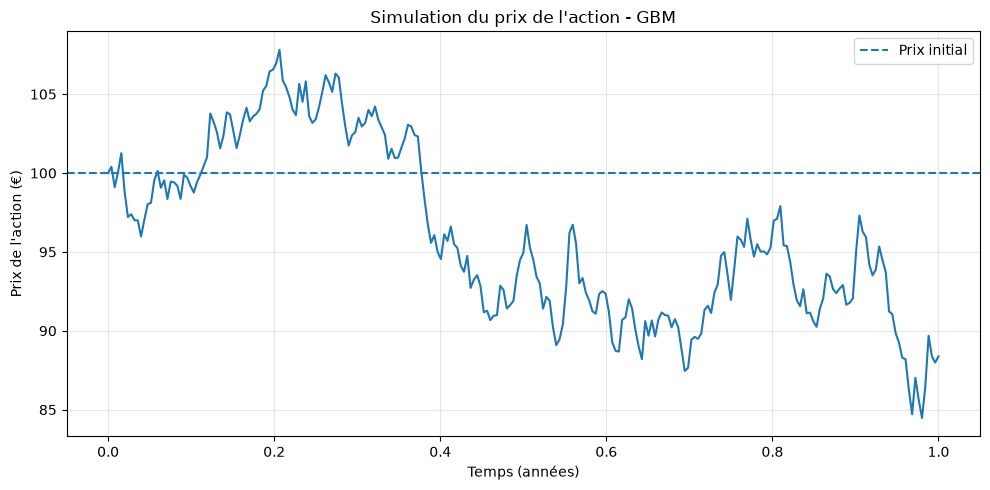

In [81]:


from src.hedging import simulate_gbm_path
import matplotlib.pyplot as plt

S0 = 100
r = 0.05
sigma = 0.20
T = 1

times, prices = simulate_gbm_path(
    S0=S0,
    r=r,
    sigma=sigma,
    T=T,
    n_steps=252,
    seed=42
)

print("Prix initial :", prices[0])
print("Prix final :", round(prices[-1], 4))
print("Prix minimum :", round(prices.min(), 4))
print("Prix maximum :", round(prices.max(), 4))

plt.figure(figsize=(10, 5))

plt.plot(times, prices)

plt.axhline(
    S0,
    linestyle="--",
    label="Prix initial"
)

plt.xlabel("Temps (années)")
plt.ylabel("Prix de l'action (€)")
plt.title("Simulation du prix de l'action - GBM")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/gbm_simulation.png", dpi=300)
plt.show()


In [82]:

from src.hedging import calculate_call_delta

S = 100
K = 100
tau = 1
r = 0.05
sigma = 0.20

delta = calculate_call_delta(
    S, K, tau, r, sigma
)

print("Delta du Call :", delta)

print("Nombre d'actions nécessaires :",
      delta)


ImportError: cannot import name 'calculate_call_delta' from 'src.hedging' (c:\Users\Admin\options-pricer-delta-hedging\src\hedging.py)